# 02 — Main Comparison: 5 methods × 4 environments

This is the paper's headline figure. Learning curves for all 5 methods
on all 4 environments. Each panel is one environment; 5 lines per panel.

**Runtime:** roughly 20 configs × N_RUNS runs × ~1-3s per run.
At N_RUNS=50: ~15 min. At N_RUNS=500: ~2.5 hours.


In [1]:
import sys, os, time
sys.path.insert(0, '..')
import numpy as np
import matplotlib.pyplot as plt

from envs import (CliffWalking, StochasticCliff,
                  CorridorCliff, StochasticCorridorCliff)
from agents import (run_sarsa, run_q_learning, run_expected_sarsa,
                    run_double_expected_sarsa, run_rr_expected_sarsa)
from utils import (multi_seed_run, smooth,
                   bootstrap_mean_ci, bootstrap_diff_ci, pairwise_table,
                   rollout_metrics, regret_to_convergence)

# ---- Run configuration ----

N_RUNS = 500
N_EPISODES = 100
EPS_DEFAULT = 0.1
ALPHA_DEFAULT = 0.3
SLIP = 0.2
RR_DELTA = 1.0   # RR-ES regret threshold used in most experiments

def sem(arr, axis=0):
    return arr.std(axis=axis, ddof=1) / np.sqrt(arr.shape[axis])

# ---- Environment factories ----
def env_det(seed=None):   return CliffWalking()
def env_stoch(seed=None): return StochasticCliff(slip_prob=SLIP, rng_seed=seed)
def env_corr(seed=None):  return CorridorCliff()
def env_scor(seed=None):  return StochasticCorridorCliff(slip_prob=SLIP, rng_seed=seed)

ENVS = {
    'Det Cliff':        env_det,
    'Stoch Cliff':      env_stoch,
    'Corr Cliff':       env_corr,
    'Stoch Corr Cliff': env_scor,
}

# ---- Method registry ----
METHODS = {
    'SARSA':          (run_sarsa,                {}),
    'Q-learning':     (run_q_learning,           {}),
    'Expected SARSA': (run_expected_sarsa,       {}),
    'Double ES':      (run_double_expected_sarsa, {}),
    f'RR-ES (δ={RR_DELTA})': (run_rr_expected_sarsa, {'delta': RR_DELTA}),
}

METHOD_COLORS = {
    'SARSA':              '#1f77b4',
    'Q-learning':         '#ff7f0e',
    'Expected SARSA':     '#2ca02c',
    'Double ES':          '#9467bd',
    f'RR-ES (δ={RR_DELTA})': '#d62728',
}
METHOD_MARKERS = {
    'SARSA':              'o',
    'Q-learning':         's',
    'Expected SARSA':     '^',
    'Double ES':          'v',
    f'RR-ES (δ={RR_DELTA})': 'D',
}


In [2]:
curves = {env_name: {} for env_name in ENVS}
per_run_data = {env_name: {} for env_name in ENVS}

t0 = time.time()
for env_name, env_fn in ENVS.items():
    print(f'\n=== {env_name} ===')
    for name, (fn, kw) in METHODS.items():
        ret = multi_seed_run(fn, env_fn, N_RUNS, N_EPISODES,
                             alpha=ALPHA_DEFAULT, eps=EPS_DEFAULT,
                             progress=True, desc=f'{name}', **kw)
        curves[env_name][name] = {
            'mean': ret.mean(axis=0),
            'sem':  sem(ret, axis=0),
            'last30_per_run': ret[:, -30:].mean(axis=1),
        }
        per_run_data[env_name][name] = ret  # keep full for stats later
print(f'\ntotal: {time.time()-t0:.0f}s')



=== Det Cliff ===


SARSA:   0%|          | 0/500 [00:00<?, ?it/s]

Q-learning:   0%|          | 0/500 [00:00<?, ?it/s]

Expected SARSA:   0%|          | 0/500 [00:00<?, ?it/s]

Double ES:   0%|          | 0/500 [00:00<?, ?it/s]

RR-ES (δ=1.0):   0%|          | 0/500 [00:00<?, ?it/s]

... (15 outputs left out)

Expected SARSA:   0%|          | 0/500 [00:00<?, ?it/s]

Double ES:   0%|          | 0/500 [00:00<?, ?it/s]

RR-ES (δ=1.0):   0%|          | 0/500 [00:00<?, ?it/s]


total: 833s


In [3]:
# save raw per-run data
safe = lambda s: s.replace(' ', '_').replace('(','').replace(')','').replace('=','_').replace('δ','delta')
np.savez('../results/data/02_main_comparison.npz',
         n_runs=N_RUNS, alpha=ALPHA_DEFAULT, eps=EPS_DEFAULT, slip=SLIP,
         **{f'{safe(env_name)}__{safe(m_name)}': arr
            for env_name, inner in per_run_data.items()
            for m_name, arr in inner.items()})
print('saved')


saved


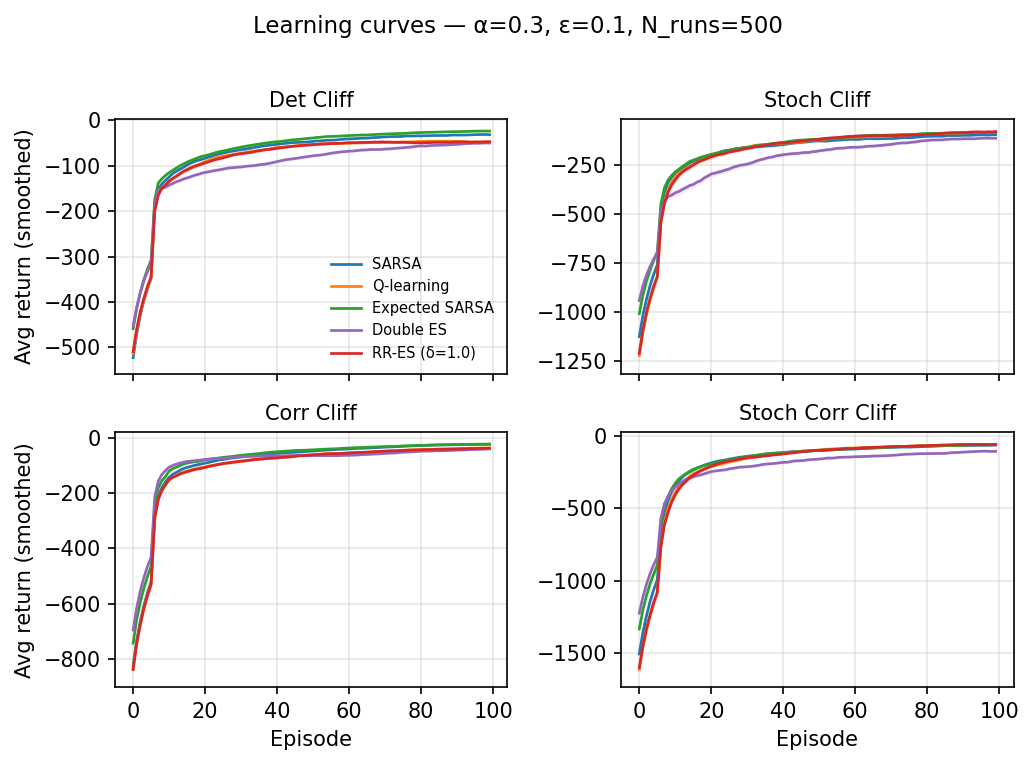

In [4]:
fig, axes = plt.subplots(2, 2, figsize=(7, 5), dpi=150, sharex=True)
axes = axes.flatten()
SMOOTH_W = 10
for ax, (env_name, env_curves) in zip(axes, curves.items()):
    for m_name, d in env_curves.items():
        m = smooth(d['mean'], SMOOTH_W)
        s = smooth(d['sem'], SMOOTH_W)
        x = np.arange(len(m))
        ax.fill_between(x, m - s, m + s,
                        color=METHOD_COLORS[m_name], alpha=0.12, linewidth=0)
        ax.plot(x, m, label=m_name, color=METHOD_COLORS[m_name], linewidth=1.3)
    ax.set_title(env_name, fontsize=10)
    ax.grid(alpha=0.3)
axes[0].set_ylabel('Avg return (smoothed)')
axes[2].set_ylabel('Avg return (smoothed)')
axes[2].set_xlabel('Episode'); axes[3].set_xlabel('Episode')
axes[0].legend(frameon=False, fontsize=7, loc='lower right')
plt.suptitle(f'Learning curves — α={ALPHA_DEFAULT}, ε={EPS_DEFAULT}, N_runs={N_RUNS}',
             y=1.01, fontsize=11)
plt.tight_layout()
plt.savefig('../results/figures/02_main_comparison.png', dpi=200, bbox_inches='tight')
plt.show()


In [5]:
# Stats table: pairwise comparisons on converged (last-30) performance per env
for env_name, env_data in per_run_data.items():
    per_run = {name: env_data[name][:, -30:].mean(axis=1) for name in env_data}
    print(f'\n###### {env_name} ######')
    pairwise_table(per_run, metric_name=f'last30 on {env_name}')



###### Det Cliff ######

Pairwise comparisons on last30 on Det Cliff (bootstrap n=5000):
Method A              Method B              diff (A-B)    95% CI                p       
------------------------------------------------------------------------------------------
SARSA                 Q-learning            13.54+++++++++[+12.29, +14.74]      0.000 **
SARSA                 Expected SARSA        -7.18+++++++++[-7.99, -6.42]        0.000 **
SARSA                 Double ES             22.07+++++++++[+20.45, +23.65]      0.000 **
SARSA                 RR-ES (δ=1.0)         14.89+++++++++[+13.66, +16.10]      0.000 **
Q-learning            Expected SARSA        -20.72++++++++[-21.86, -19.64]      0.000 **
Q-learning            Double ES             8.52++++++++++[+6.67, +10.31]       0.000 **
Q-learning            RR-ES (δ=1.0)         1.35++++++++++[-0.14, +2.77]        0.075 
Expected SARSA        Double ES             29.25+++++++++[+27.70, +30.79]      0.000 **
Expected SARSA      

SARSA                 Q-learning            -13.40++++++++[-18.24, -8.62]       0.000 **
SARSA                 Expected SARSA        -14.06++++++++[-19.05, -9.25]       0.000 **
SARSA                 Double ES             20.49+++++++++[+14.85, +26.03]      0.000 **
SARSA                 RR-ES (δ=1.0)         -13.73++++++++[-18.75, -8.81]       0.000 **
Q-learning            Expected SARSA        -0.66+++++++++[-4.92, +3.48]        0.750 
Q-learning            Double ES             33.88+++++++++[+28.84, +38.80]      0.000 **
Q-learning            RR-ES (δ=1.0)         -0.34+++++++++[-4.63, +3.95]        0.859 
Expected SARSA        Double ES             34.54+++++++++[+29.57, +39.54]      0.000 **
Expected SARSA        RR-ES (δ=1.0)         0.33++++++++++[-3.97, +4.70]        0.899 
Double ES             RR-ES (δ=1.0)         -34.22++++++++[-39.40, -29.23]      0.000 **

###### Corr Cliff ######

Pairwise comparisons on last30 on Corr Cliff (bootstrap n=5000):
Method A              Me

SARSA                 Double ES             20.41+++++++++[+19.12, +21.72]      0.000 **
SARSA                 RR-ES (δ=1.0)         15.23+++++++++[+14.31, +16.16]      0.000 **
Q-learning            Expected SARSA        -15.04++++++++[-15.82, -14.24]      0.000 **
Q-learning            Double ES             6.16++++++++++[+4.82, +7.56]        0.000 **
Q-learning            RR-ES (δ=1.0)         0.98++++++++++[-0.03, +1.98]        0.058 
Expected SARSA        Double ES             21.19+++++++++[+19.98, +22.48]      0.000 **
Expected SARSA        RR-ES (δ=1.0)         16.01+++++++++[+15.14, +16.87]      0.000 **
Double ES             RR-ES (δ=1.0)         -5.18+++++++++[-6.60, -3.74]        0.000 **

###### Stoch Corr Cliff ######

Pairwise comparisons on last30 on Stoch Corr Cliff (bootstrap n=5000):
Method A              Method B              diff (A-B)    95% CI                p       
------------------------------------------------------------------------------------------
SARSA 

Q-learning            Expected SARSA        1.62++++++++++[-1.16, +4.48]        0.263 
Q-learning            Double ES             52.59+++++++++[+48.75, +56.36]      0.000 **
Q-learning            RR-ES (δ=1.0)         -0.40+++++++++[-3.17, +2.28]        0.761 
Expected SARSA        Double ES             50.97+++++++++[+47.04, +54.89]      0.000 **
Expected SARSA        RR-ES (δ=1.0)         -2.02+++++++++[-4.78, +0.79]        0.152 
Double ES             RR-ES (δ=1.0)         -52.99++++++++[-56.95, -49.12]      0.000 **


### Interpretation guide

For each environment, look for three things:

1. **Ordering at convergence** — which method has the highest last-30 return? 
2. **Learning speed** — which method reaches high return earliest?
3. **Variability** — which method's SEM band is narrowest? (= most reliable)

The pairwise tables show which differences are statistically significant (p<0.05 marked *).
